# 03 — Model Training, Imbalance Handling, Tuning & Evaluation

Reviews the benchmark results across Logistic Regression, Random Forest, and XGBoost (comparing unweighted baseline, class weighting, inside-fold SMOTE, and RandomizedSearchCV tuning).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display
from src.config import MODEL_COMPARISON_CSV_PATH, EVALUATION_SUMMARY_PATH, METADATA_PATH, FIGURES_DIR

comp_df = pd.read_csv(MODEL_COMPARISON_CSV_PATH)
comp_df[['model_name', 'stage', 'cv_roc_auc', 'cv_pr_auc', 'cv_f1', 'roc_auc', 'pr_auc', 'f1_score', 'recall', 'precision', 'accuracy']]

,model_name,stage,cv_roc_auc,cv_pr_auc,cv_f1,roc_auc,pr_auc,f1_score,recall,precision,accuracy
0,XGBoost (Tuned),tuned,0.8500,0.6677,0.6323,0.8464,0.6648,0.6197,0.7995,0.5059,0.7395
1,Random Forest (Tuned),tuned,0.8477,0.6646,0.6297,0.8424,0.6503,0.6290,0.7888,0.5230,0.7530
2,XGBoost (Weighted),comparison,0.8471,0.6618,0.6340,0.8460,0.6569,0.6378,0.7888,0.5354,0.7622
3,Random Forest (Balanced),comparison,0.8462,0.6622,0.6337,0.8420,0.6559,0.6276,0.7727,0.5283,0.7566
4,Logistic Regression (Tuned),tuned,0.8458,0.6617,0.6290,0.8414,0.6323,0.6123,0.7834,0.5026,0.7367
5,Baseline Logistic Regression (Unweighted),comparison,0.8458,0.6630,0.5957,0.8426,0.6378,0.5804,0.5214,0.6544,0.7999
6,Logistic Regression (Balanced),comparison,0.8456,0.6620,0.6251,0.8422,0.6363,0.6146,0.7888,0.5034,0.7374
7,XGBoost (SMOTE),comparison,0.8448,0.6547,0.6039,0.8471,0.6644,0.6006,0.5749,0.6287,0.7970
8,Logistic Regression (SMOTE),comparison,0.8439,0.6600,0.6306,0.8406,0.6336,0.6175,0.7941,0.5051,0.7388
9,Random Forest (SMOTE),comparison,0.8423,0.6420,0.6127,0.8365,0.6361,0.5987,0.6123,0.5857,0.7821


In [2]:
with open(METADATA_PATH, 'r', encoding='utf-8') as f:
    meta = json.load(f)
print('Selected Model:', meta['selected_model'])
print('Selection Criterion:', meta['selection_criterion'])
print('Best Hyperparameters:', meta['best_hyperparameters'])
print('Held-out Test Metrics:', meta['selected_model_test_metrics'])

Selected Model: XGBoost (Tuned)
Selection Criterion: 0.45 * CV_ROC_AUC + 0.30 * CV_PR_AUC + 0.25 * CV_F1 (selected on CV folds only; never accuracy alone)
Best Hyperparameters: {'classifier__subsample': 0.8, 'classifier__reg_lambda': 5.0, 'classifier__n_estimators': 320, 'classifier__min_child_weight': 3, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.75}
Held-out Test Metrics: {'threshold': 0.5, 'accuracy': 0.7395, 'precision': 0.5059, 'recall': 0.7995, 'f1_score': 0.6197, 'roc_auc': 0.8464, 'pr_auc': 0.6648, 'confusion_matrix': {'tn': 743, 'fp': 292, 'fn': 75, 'tp': 299}}


09_model_comparison.png


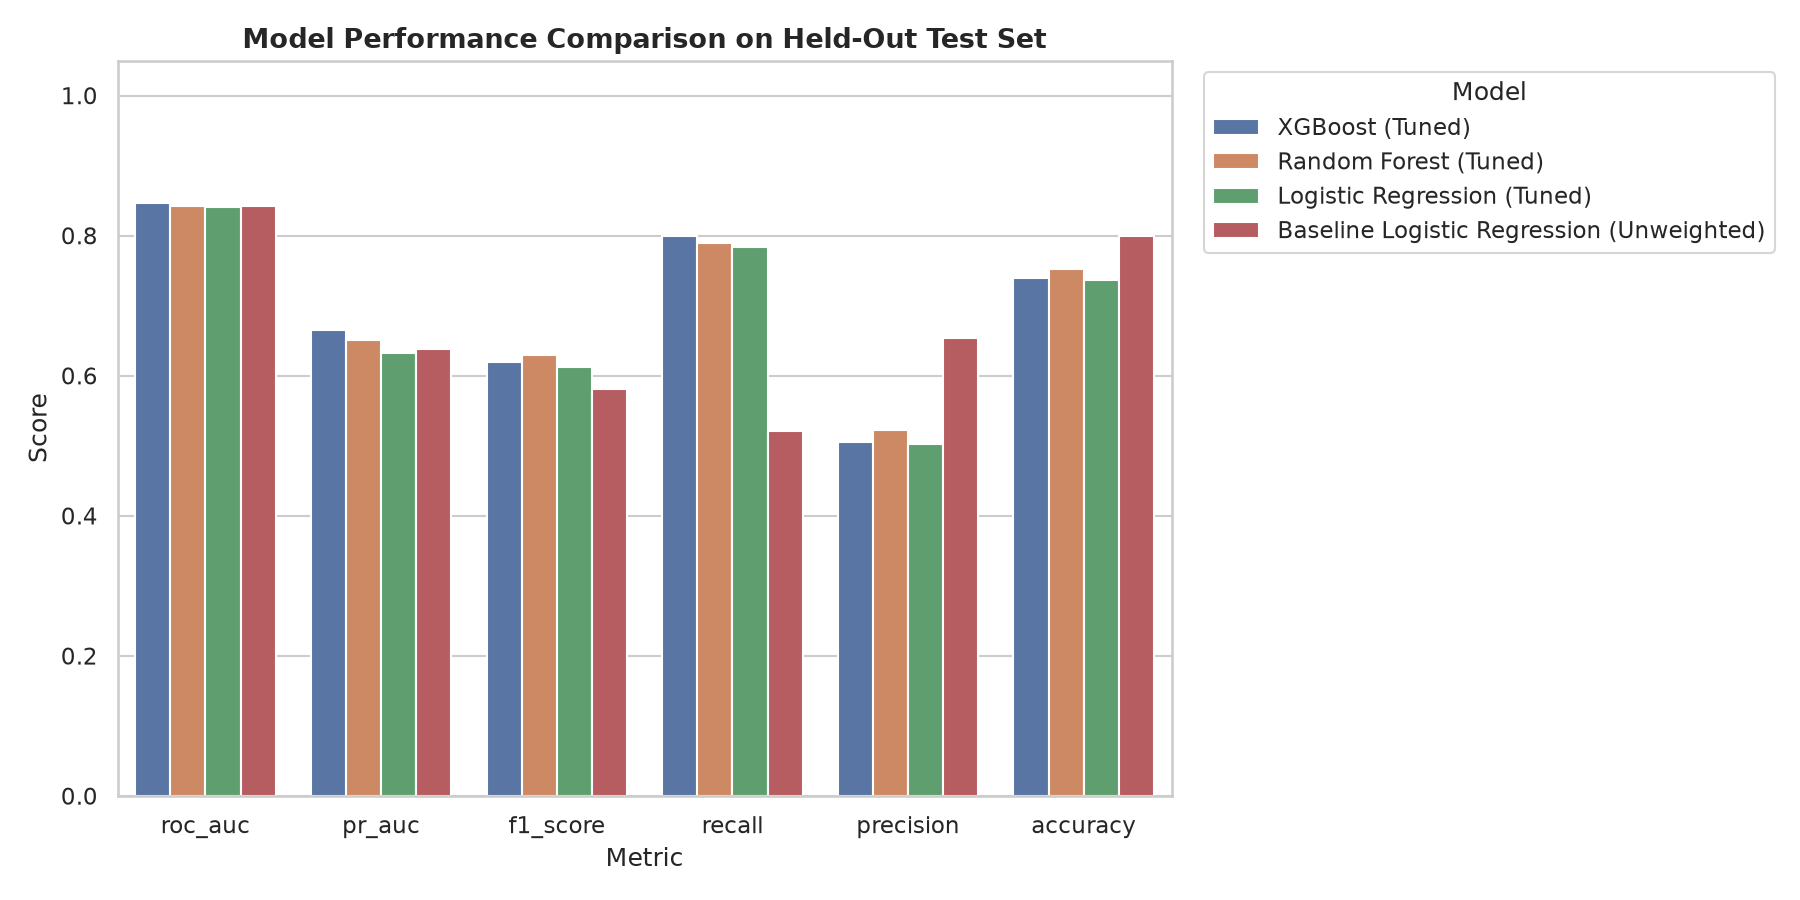

10_roc_curves.png


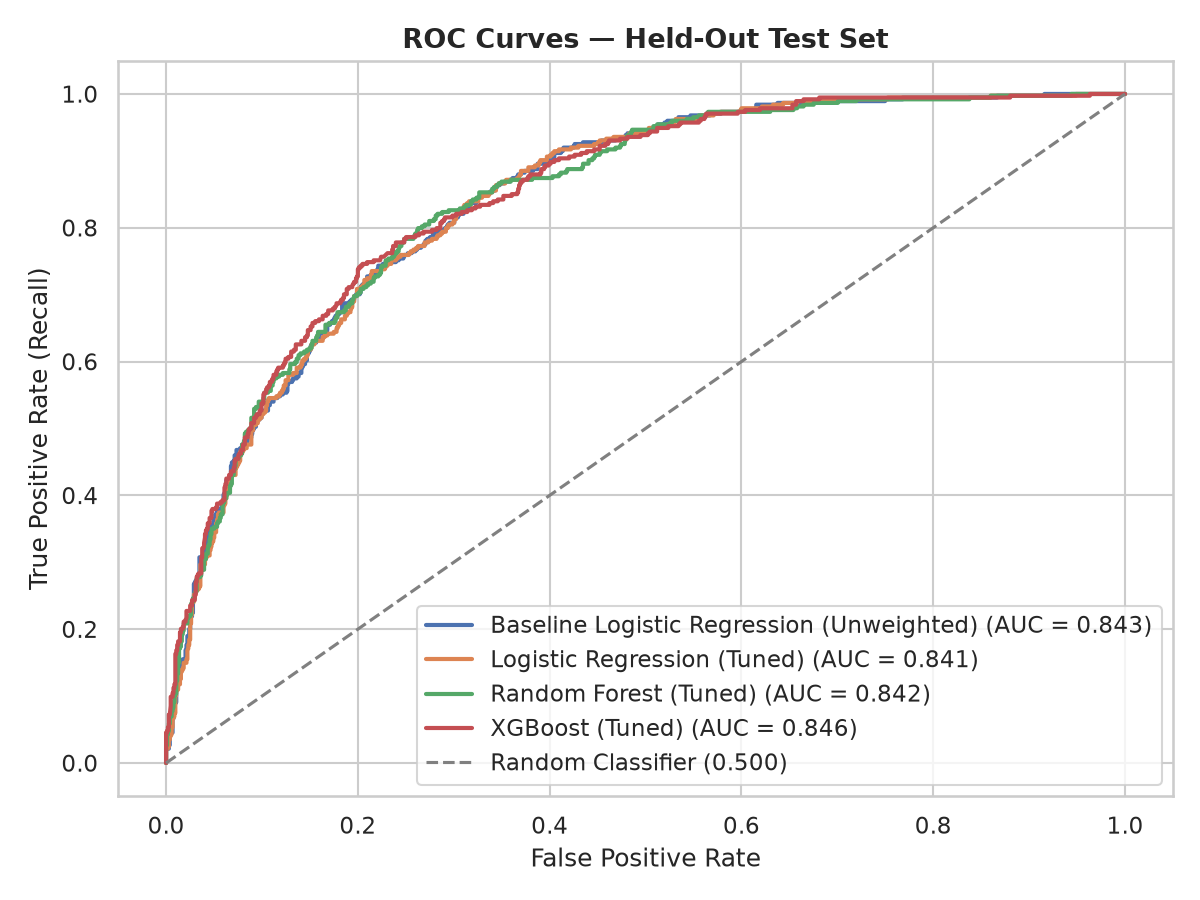

11_pr_curves.png


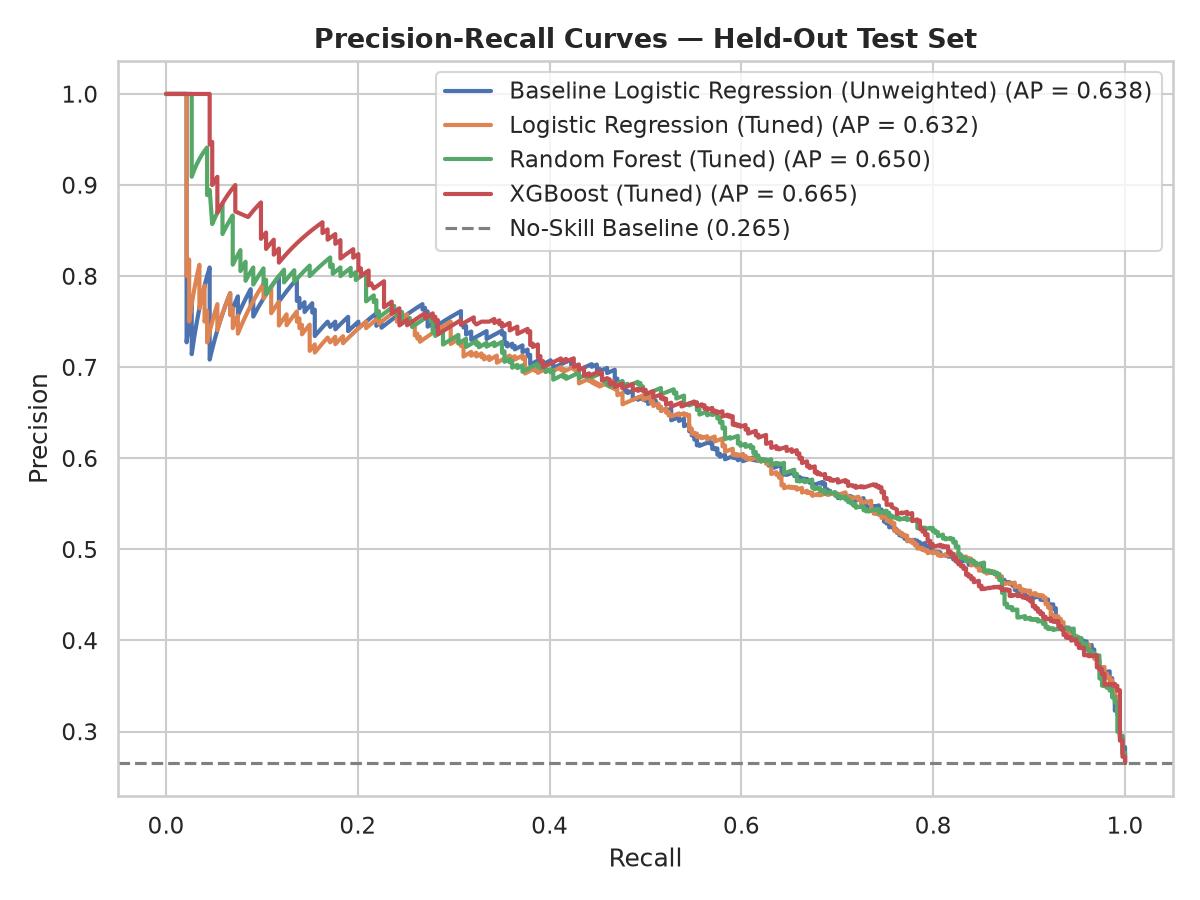

12_confusion_matrix_best.png


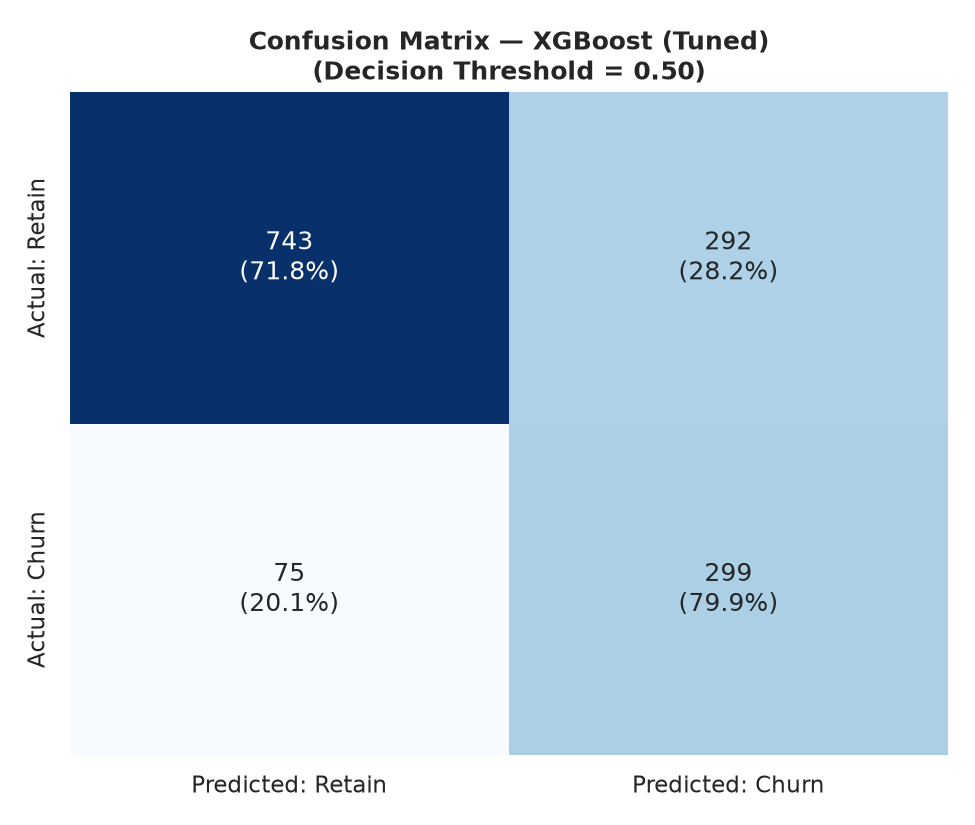

13_threshold_analysis.png


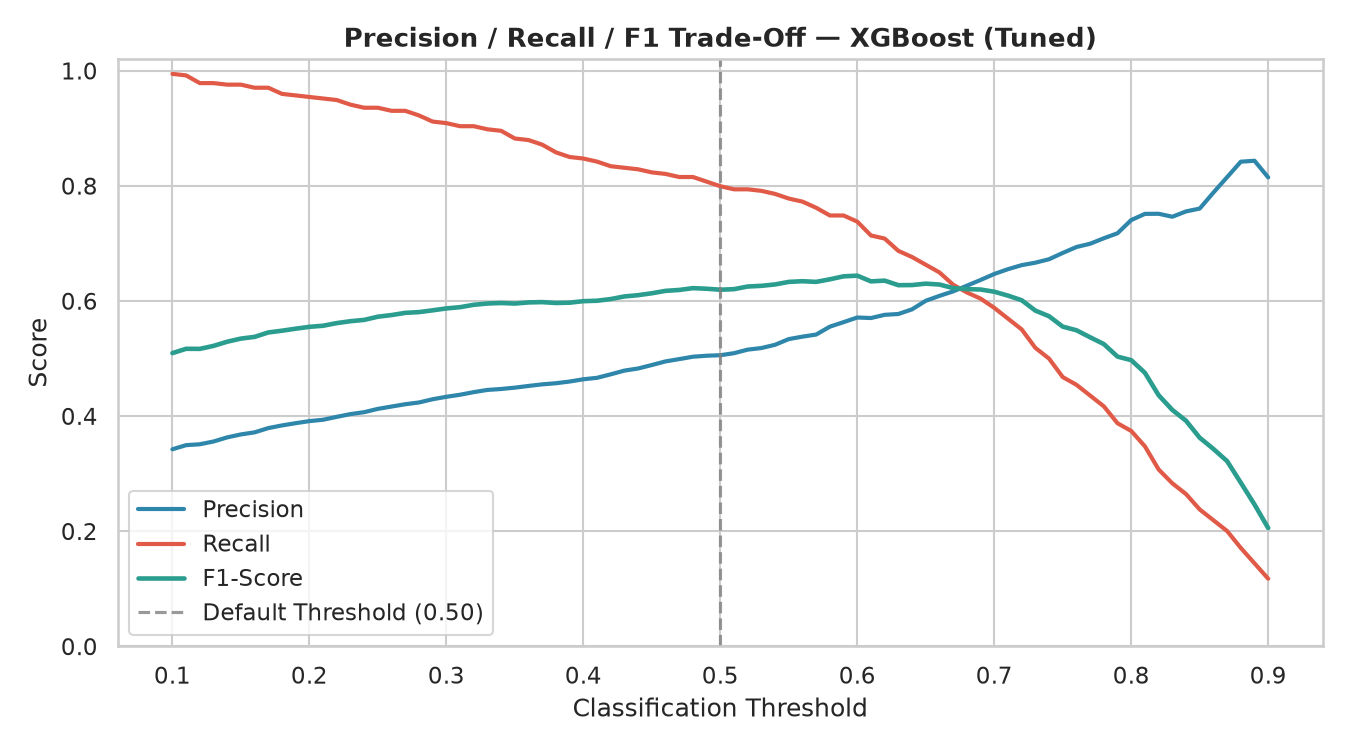

In [3]:
for fname in ['09_model_comparison.png', '10_roc_curves.png', '11_pr_curves.png', '12_confusion_matrix_best.png', '13_threshold_analysis.png']:
    p = FIGURES_DIR / fname
    if p.exists():
        print(fname)
        display(Image(filename=str(p), width=750))